Project folder found: C:\Users\hp\Downloads\ECO346-A1-FA24-BEDS-047-main\ECO346-A1-FA24-BEDS-047-main


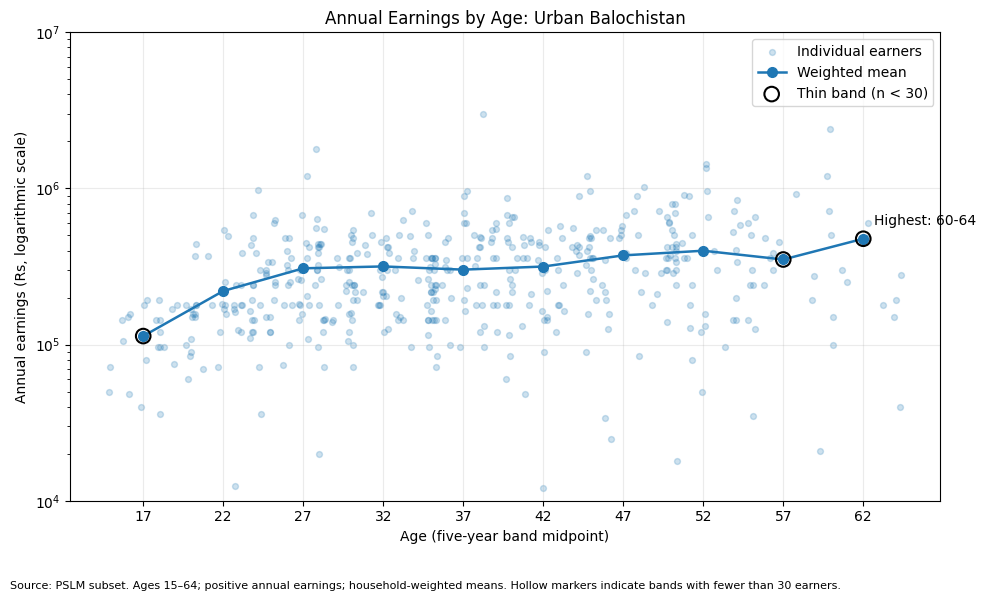


Eligible earners: 486

Age-band table:
age_band  midpoint  n_earners  weighted_mean_earnings  thin
   15-19        17         22                  113382  True
   20-24        22         56                  220435 False
   25-29        27         69                  307994 False
   30-34        32         62                  316659 False
   35-39        37         80                  302071 False
   40-44        42         60                  316147 False
   45-49        47         47                  372723 False
   50-54        52         55                  399250 False
   55-59        57         19                  350772  True
   60-64        62         16                  476422  True

Mean earnings for ages 25–29:
307994

Mean earnings for ages 45–49:
372723

Highest-mean age band: 60-64
Weighted mean earnings: Rs 476,422

Saved table: C:\Users\hp\Downloads\ECO346-A1-FA24-BEDS-047-main\ECO346-A1-FA24-BEDS-047-main\figures\q5_python_age_band_table.csv
Saved chart: C:\Users\hp\Dow

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Find the project folder automatically
required_files = [
    "data/pslm_person_subset.csv",
    "data/pslm_hh_subset.csv"
]

ROOT = None

# First search the current folder and its parent folders
for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if all((folder / file).is_file() for file in required_files):
        ROOT = folder
        break

# If Jupyter starts elsewhere, search Downloads as a fallback
if ROOT is None:
    downloads = Path.home() / "Downloads"
    if downloads.exists():
        for person_file in downloads.rglob("pslm_person_subset.csv"):
            candidate = person_file.parent.parent
            if all((candidate / file).is_file() for file in required_files):
                ROOT = candidate
                break

if ROOT is None:
    raise FileNotFoundError(
        "Project data files not found. Check that both CSV files "
        "are inside your project's data folder."
    )

DATA = ROOT / "data"
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

print("Project folder found:", ROOT)

# 2. Load the data
persons = pd.read_csv(DATA / "pslm_person_subset.csv")
households = pd.read_csv(DATA / "pslm_hh_subset.csv")

# 3. Join person and household information
df = persons.merge(
    households[["hhid", "hhweight", "prov_code", "urban_rural"]],
    on="hhid",
    how="inner"
)

# 4. Convert required columns to numeric
for col in ["age", "earn_annual", "hhweight", "prov_code", "urban_rural"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 5. Filter: urban Balochistan, ages 15–64, positive earnings and weights
df = df[
    (df["prov_code"] == 4) &
    (df["urban_rural"] == 2) &
    (df["age"] >= 15) &
    (df["age"] <= 64) &
    (df["earn_annual"] > 0) &
    (df["hhweight"] > 0) &
    np.isfinite(df["age"]) &
    np.isfinite(df["earn_annual"]) &
    np.isfinite(df["hhweight"])
].copy()

df["age"] = df["age"].astype(int)

if df.empty:
    raise ValueError("No eligible earners found. Check the data and filters.")

# 6. Create five-year age bands and weighted mean earnings
df["age_band_start"] = (df["age"] // 5) * 5
df["age_band_start"] = df["age_band_start"].clip(lower=15, upper=60)

summary_rows = []

for start in range(15, 65, 5):
    group = df[df["age_band_start"] == start]

    if group.empty:
        summary_rows.append({
            "age_band": f"{start}-{start+4}",
            "midpoint": start + 2,
            "n_earners": 0,
            "weighted_mean_earnings": np.nan,
            "thin": True
        })
        continue

    mean_earnings = np.average(
        group["earn_annual"],
        weights=group["hhweight"]
    )

    summary_rows.append({
        "age_band": f"{start}-{start+4}",
        "midpoint": start + 2,
        "n_earners": len(group),
        "weighted_mean_earnings": int(np.floor(mean_earnings + 0.5)),
        "thin": len(group) < 30
    })

summary = pd.DataFrame(summary_rows)

# 7. Save the table
table_file = FIGURES / "q5_python_age_band_table.csv"
summary.to_csv(table_file, index=False)

# 8. Draw the age-profile chart
fig, ax = plt.subplots(figsize=(10, 6))

# Individual earners, with a small horizontal jitter
rng = np.random.default_rng(346)
jitter = rng.uniform(-0.35, 0.35, size=len(df))

ax.scatter(
    df["age"] + jitter,
    df["earn_annual"],
    alpha=0.22,
    s=18,
    label="Individual earners"
)

# Weighted mean earnings by age band
valid = summary[summary["n_earners"] > 0].copy()

ax.plot(
    valid["midpoint"],
    valid["weighted_mean_earnings"],
    linewidth=1.8,
    marker="o",
    markersize=7,
    label="Weighted mean"
)

# Hollow markers identify thin age bands
thin = valid[valid["thin"]]
ax.scatter(
    thin["midpoint"],
    thin["weighted_mean_earnings"],
    facecolors="none",
    edgecolors="black",
    s=110,
    linewidths=1.5,
    label="Thin band (n < 30)",
    zorder=5
)

# Label the age band with the highest weighted mean
highest = valid.loc[valid["weighted_mean_earnings"].idxmax()]
ax.annotate(
    f"Highest: {highest['age_band']}",
    (highest["midpoint"], highest["weighted_mean_earnings"]),
    xytext=(8, 10),
    textcoords="offset points"
)

ax.set_yscale("log")
ax.set_ylim(10_000, 10_000_000)
ax.set_xticks(range(17, 63, 5))
ax.set_xlabel("Age (five-year band midpoint)")
ax.set_ylabel("Annual earnings (Rs, logarithmic scale)")
ax.set_title("Annual Earnings by Age: Urban Balochistan")
ax.grid(True, which="major", alpha=0.25)
ax.legend()
fig.text(
    0.01, 0.01,
    "Source: PSLM subset. Ages 15–64; positive annual earnings; "
    "household-weighted means. Hollow markers indicate bands with fewer than 30 earners.",
    fontsize=8
)
fig.tight_layout(rect=[0, 0.06, 1, 1])

plot_file = FIGURES / "q5_python_age_profile.svg"
fig.savefig(plot_file, format="svg", bbox_inches="tight")
plt.show()
plt.close(fig)

# 9. Show results
print("\nEligible earners:", len(df))
print("\nAge-band table:")
print(summary.to_string(index=False))

print("\nMean earnings for ages 25–29:")
print(summary.loc[summary["age_band"] == "25-29", "weighted_mean_earnings"].to_string(index=False))

print("\nMean earnings for ages 45–49:")
print(summary.loc[summary["age_band"] == "45-49", "weighted_mean_earnings"].to_string(index=False))

print("\nHighest-mean age band:", highest["age_band"])
print("Weighted mean earnings: Rs", f"{int(highest['weighted_mean_earnings']):,}")

print("\nSaved table:", table_file)
print("Saved chart:", plot_file)